# STIL - Extração e Análise de Corpus
Grupo 04

Fluxo completo:
1. Scraping dos metadados dos artigos + download dos PDFs
2. Conversão dos PDFs para Markdown UTF-8, em pastas separadas por idioma
3. Limpeza (`Abstract`/`Keywords`, referências, `et al.`, LaTeX, código e artefatos de Markdown)
4. Tokenização, POS tagging e lematização (spaCy), **sem remoção de stopwords e sem conversão para lowercase**
5. Geração de corpora JSON separados para português e inglês
6. Estatísticas (tokens, types, sentenças, POS, lemas, top10, nuvem de palavras)
7. Estatísticas por artigo e média de unidades lexicais

### Alterações aplicadas e consequências

- **Sem lowercase:** aplicado aos cálculos de types, lemas únicos, frequências e estatísticas por artigo. A caixa original é preservada; por isso, por exemplo, `Corpus` e `corpus` passam a ser types distintos.
- **Sem `et al.`:** removido do corpo dos artigos durante a limpeza, antes do spaCy. Metadados de autores e referências continuam intactos; apenas a abreviação de citação deixa de influenciar frequências e contagens.
- **UTF-8 + correção de diacríticos do PDF:** os Markdown e JSON continuam em UTF-8. Antes da normalização Unicode, acentos que o PDF extrai como glifos espaçadores (`´a`, `´ı`, `ˆe`, `˜a`, `c¸`) são recolocados sobre a letra correta; a forma degradada `◌́ı` também é reparada. Depois o texto é normalizado em NFKC. Isso corrige a extração do PDF sem reinterpretar os bytes como Latin-1.
- **PDF para Markdown:** `pymupdf4llm` substitui a extração de texto simples. Títulos, parágrafos e listas tendem a ser preservados melhor, mas a ordem final ainda depende da estrutura interna de cada PDF.
- **Corpus por língua:** os Markdown ficam em `corpus_markdown/pt` e `corpus_markdown/en`; os resultados finais ficam em `corpus_final_pt.json` e `corpus_final_en.json`. Consumidores do antigo `corpus_final.json` precisam passar a ler um ou ambos os novos arquivos.
- **Filtro de conteúdo e artefatos:** executado no Markdown antes da análise linguística. Os blocos em inglês `Abstract` e `Keywords` são retirados somente do corpo analisado; os campos de metadados continuam no JSON. Blocos e trechos de código, LaTeX, imagens, tabelas, URLs e marcação residual também não entram no corpus. Conteúdo linguístico que exista apenas nesses elementos deixa de ser contado.
- **Média lexical:** ao fim das estatísticas por artigo, conta tokens alfabéticos como unidades lexicais e mostra a média geral e por idioma. Pontuação, símbolos e números não entram nessa medida.
- **Nuvem sem palavras agrupadas:** a nuvem é gerada diretamente das frequências dos tokens, com `collocations=False`. Cada item visual corresponde exatamente a um token do corpus, sem bigramas automáticos.

## 0. Instalação de dependências

In [ ]:
!pip install pymupdf4llm spacy wordcloud unidecode beautifulsoup4 requests -q
!python -m spacy download pt_core_news_lg -q
!python -m spacy download en_core_web_lg -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.4/176.4 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 39.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.9/42.9 MB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 235.8/235.8 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 33.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 568.2/568.2 MB 3.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_lg')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.7/400.7 MB 4.1 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_lg')
⚠ 

## 1. Imports

In [ ]:
from functools import cache
from unidecode import unidecode
import requests
import urllib.parse
from bs4 import BeautifulSoup
import json
import re
import unicodedata
from pathlib import Path
from collections import Counter
import pandas as pd
import pymupdf4llm
import spacy
from wordcloud import WordCloud
import matplotlib.pyplot as plt

## 2. Scraping dos metadados + download dos PDFs
`ISSUE_URL` é a página da edição do STIL no SOL/SBC (troque conforme o ano/grupo).

In [ ]:
ISSUE_URL = "https://sol.sbc.org.br/index.php/stil/issue/view/841"


def fetch_articles():
    lang_map = {"PDF (English)": "en", "PDF": "pt"}
    response_articles = requests.get(ISSUE_URL)

    print(f"Requested main page of articles, response status => {response_articles.status_code}.")

    response_soup = BeautifulSoup(response_articles.text, "html.parser")
    articles_soup = response_soup.select('#pkp_content_main .obj_issue_toc .sections > div:nth-child(2) > ul > li')

    print(f"Found {len(articles_soup)} articles.")

    articles = []
    for article_soup in articles_soup:
        title = article_soup.select_one(".title a").get_text(strip=True)
        url = article_soup.select_one(".title a").get('href')
        url_pdf = article_soup.select_one('.galleys_links a').get('href')
        pages = article_soup.select_one(".meta .pages").get_text(strip=True)
        lang = lang_map[article_soup.select_one('.galleys_links a').get_text(strip=True)]
        article_metadata = {"title": title, "url": url, "url_pdf": url_pdf, "pages": pages, "lang": lang}
        articles.append(article_metadata)
    return articles


def fetch_article_pdf(article):
    url_download = article['url_pdf'].replace('view', 'download')
    filename = f"{'-'.join(url_download.split('/')[-2:])}.pdf"
    file_path = Path(f"files/{article['lang']}/{filename}")
    file_path.parent.mkdir(parents=True, exist_ok=True)

    with requests.get(url_download, stream=True) as response:
        response.raise_for_status()
        with open(file_path, "wb") as file:
            for chunk in response.iter_content(chunk_size=8192):
                file.write(chunk)

    return str(file_path)


def fetch_article_info(article):
    response = requests.get(article["url"])

    print(f"Requested article, response status => {response.status_code}.")
    response_soup = BeautifulSoup(response.text, "html.parser")

    authors_names = [item.get('content').strip() for item in response_soup.find_all('meta', {'name': 'citation_author'})]
    institutions_names = [item.get('content').strip() for item in response_soup.find_all('meta', {'name': 'citation_author_institution'})]
    authors = []
    for index, author_name in enumerate(authors_names):
        institution = institutions_names[index] if index < len(institutions_names) else ""
        authors.append({'name': author_name, 'institution': institution})

    abstract_pt_tag = response_soup.find('meta', {'name': 'DC.Description', 'xml:lang': 'pt'})
    abstract_en_tag = response_soup.find('meta', {'name': 'DC.Description', 'xml:lang': 'en'})
    abstract_pt = abstract_pt_tag.get('content') if abstract_pt_tag else None
    abstract_en = abstract_en_tag.get('content') if abstract_en_tag else None

    publish_date_tag = response_soup.select_one('.published .value')
    publish_date = publish_date_tag.get_text(strip=True) if publish_date_tag else ""

    refs_tag = response_soup.select_one('.references .value')
    refs = refs_tag.get_text(separator="\n").split('\n') if refs_tag else []
    references = [ref.strip() for ref in refs if not (len(ref) < 10 or ref == '[link]' or ref == '.')]

    file_path = fetch_article_pdf(article)

    keywords_tags = response_soup.find_all('meta', {'name': 'citation_keywords'})
    keywords = [t.get('content').strip() for t in keywords_tags if t.get('content')]

    result = {
        "publish_date": publish_date,
        "authors": authors,
        "file_path": file_path,
        "references": references,
        "keywords": keywords,
    }

    if abstract_en == abstract_pt:
        result["abstract_en"] = abstract_en
    else:
        result["abstract_pt"] = abstract_pt
        result["abstract_en"] = abstract_en

    return result


@cache
def fetch_author_orcid(author_name):
    response = requests.get(
        f"https://pub.orcid.org/v3.0/expanded-search/?q=%7B!edismax%20qf%3D%22given-and-family-names%5E50.0%20"
        f"family-name%5E10.0%20given-names%5E10.0%20credit-name%5E10.0%20other-names%5E5.0%20text%5E1.0%22%20pf%3D%22given-and-family-names"
        f"%5E50.0%22%20bq%3D%22current-institution-affiliation-name%3A%5B*%20TO%20*%5D%5E100.0%20past-institution-affiliation-name"
        f"%3A%5B*%20TO%20*%5D%5E70%22%20mm%3D1%7D{urllib.parse.quote(author_name)}&start=0&rows=1",
        headers={"Accept": "application/json"}
    )

    print(f"Requested ORCID for {author_name}, response status => {response.status_code}.")
    response_json = response.json()

    result = response_json["expanded-result"]
    if len(result) == 0:
        print(f"No results for {author_name}.")
        return None

    given_name = result[0].get("given-names")
    family_name = result[0].get("family-names")
    if (not given_name
        or not family_name
        or unidecode(given_name.replace("-", " ")) not in unidecode(author_name)
        or unidecode(family_name.replace("-", " ")) not in unidecode(author_name)
    ):
        print(f"No results for {author_name}, no matching author.")
        return None

    return result[0]["orcid-id"]

In [ ]:
def scrape_all():
    articles = fetch_articles()

    for article in articles:
        article_info = fetch_article_info(article)
        article.update(article_info)

        for author in article["authors"]:
            orcid = fetch_author_orcid(author["name"])
            if orcid:
                author['orcid'] = orcid

    with open("output.json", "w", encoding="utf-8") as f:
        json.dump(articles, f, ensure_ascii=False, indent=4)

    return articles


articles = scrape_all()

Requested main page of articles, response status => 200.
Found 31 articles.
Requested article, response status => 200.
Requested ORCID for Thiago Alexandre Salgueiro Pardo, response status => 200.
Requested ORCID for Magali Sanches Duran, response status => 200.
Requested ORCID for Lucelene Lopes, response status => 200.
Requested ORCID for Ariani Di Felippo, response status => 200.
Requested ORCID for Norton Trevisan Roman, response status => 200.
Requested ORCID for Maria das Graças Volpe Nunes, response status => 200.
Requested article, response status => 200.
Requested ORCID for Ana Luiza Nunes, response status => 200.
No results for Ana Luiza Nunes, no matching author.
Requested ORCID for Alexandre Rademaker, response status => 200.
Requested ORCID for Leonel Figueiredo de Alencar, response status => 200.
Requested article, response status => 200.
Requested ORCID for Wellington José Leite da Silva, response status => 200.
No results for Wellington José Leite da Silva, no matching 

## 3. Carregar `output.json` (metadados + caminhos dos PDFs)

In [ ]:
with open("output.json", encoding="utf-8") as f:
    articles = json.load(f)

print(f"{len(articles)} artigos carregados de output.json")

31 artigos carregados de output.json


## 4. Conversão dos PDFs para Markdown UTF-8

In [ ]:
_PDF_DIACRITICS = {
    "´": "\u0301",
    "`": "\u0300",
    "ˆ": "\u0302",
    "˜": "\u0303",
    "¨": "\u0308",
    "¸": "\u0327",
}


def normalize_pdf_unicode(text):
    # Alguns PDFs representam o acento como glifo separado, não como marca
    # combinante. UTF-8 e NFC, sozinhos, não corrigem essa representação.
    # Repara também “ ◌́ı”, produzido quando um ´ı legado passou por NFKC.
    text = re.sub(r'[ \t]*\u0301\u0131', 'í', text)
    text = re.sub(
        r'([AEIOUaeiou])<sup>\s*([´`ˆ˜¨])\s*</sup>',
        lambda match: match.group(1) + _PDF_DIACRITICS[match.group(2)],
        text,
    )
    text = re.sub(
        r'([´`ˆ˜¨])([AEIOUYaeiouyı])',
        lambda match: (
            ("i" if match.group(2) == "ı" else match.group(2))
            + _PDF_DIACRITICS[match.group(1)]
        ),
        text,
    )
    text = re.sub(
        r'([Cc])¸',
        lambda match: match.group(1) + _PDF_DIACRITICS["¸"],
        text,
    )
    return unicodedata.normalize("NFKC", text)


def convert_pdf_to_markdown(file_path):
    pdf_path = Path(file_path)
    markdown_path = Path("corpus_markdown") / pdf_path.parent.name / f"{pdf_path.stem}.md"
    markdown_path.parent.mkdir(parents=True, exist_ok=True)

    markdown = normalize_pdf_unicode(pymupdf4llm.to_markdown(pdf_path))
    with open(markdown_path, "w", encoding="utf-8", newline="\n") as file:
        file.write(markdown)

    return str(markdown_path)


def read_markdown_utf8(markdown_path):
    with open(markdown_path, encoding="utf-8") as file:
        return normalize_pdf_unicode(file.read())

## 5. Limpeza do Markdown

- Remove do corpo analisado os blocos em inglês `Abstract` e `Keywords`, preservando os respectivos metadados no JSON.
- Corta o texto a partir da seção de Referências/References (já temos as referências separadas no `output.json`).
- Remove `et al.`, hifenização de fim de linha, LaTeX, código, imagens, tabelas, URLs e marcação Markdown residual antes da análise linguística.

In [ ]:
def remove_english_abstract_and_keywords(markdown):
    decoration = r'[*_]*'
    abstract = rf'{decoration}Abstract\s*[.:—-]?{decoration}'
    keywords = rf'{decoration}Key\s*words?\s*[.:—-]?{decoration}'
    heading = r'\s{0,3}#{1,6}\s*'

    # Seção Abstract representada por um título Markdown.
    text = re.sub(
        rf'(?ims)^{heading}{abstract}\s*$.*?(?=^{heading}(?!{abstract}\s*$)\S|\Z)',
        ' ',
        markdown,
    )

    # Formato real dos PDFs: **_Abstract._** texto até a linha em branco.
    text = re.sub(
        rf'(?ims)^\s*(?:{heading})?{abstract}\s+.*?(?=^\s*$|\Z)',
        ' ',
        text,
    )

    # Linha ou bloco de Keywords, inclusive **_Keywords:_** e **Keywords:**.
    text = re.sub(
        rf'(?ims)^\s*(?:{heading})?{keywords}\s*.*?(?=^\s*$|^{heading}\S|\Z)',
        ' ',
        text,
    )
    return text


def cut_before_references(markdown):
    heading = r'(?:Refer[eê]ncias(?:\s+Bibliogr[aá]ficas)?|References)'
    match = re.search(
        rf'(?im)^\s{{0,3}}#{{0,6}}\s*[*_]*{heading}\s*:?\s*[*_]*\s*$',
        markdown,
    )
    return markdown[:match.start()] if match else markdown


def clean_article_markdown(markdown):
    text = cut_before_references(normalize_pdf_unicode(markdown))
    text = remove_english_abstract_and_keywords(text)

    # Código e conteúdo incorporado.
    text = re.sub(r'(?ms)^\s*```.*?^\s*```\s*$', ' ', text)
    text = re.sub(r'(?ms)^\s*~~~.*?^\s*~~~\s*$', ' ', text)
    text = re.sub(r'(?is)<(pre|code)\b[^>]*>.*?</\1>', ' ', text)
    text = re.sub(r'`+[^`]*`+', ' ', text)

    # Fórmulas e ambientes LaTeX.
    latex_environment = r'equation\*?|align\*?|gather\*?|multline\*?|displaymath|math|array|matrix|cases'
    text = re.sub(
        rf'(?s)\\begin\{{({latex_environment})\}}.*?\\end\{{\1\}}',
        ' ',
        text,
    )
    text = re.sub(r'(?s)\$\$.*?\$\$|\\\[.*?\\\]|\\\(.*?\\\)', ' ', text)
    text = re.sub(r'(?<!\\)\$(?!\$)[^$\n]+?(?<!\\)\$', ' ', text)

    # Artefatos gerados pela conversão para Markdown.
    text = re.sub(r'!\[[^\]]*\]\([^)]*\)', ' ', text)
    text = re.sub(r'\[([^\]]+)\]\([^)]*\)', r'\1', text)
    text = re.sub(r'(?im)^\s*\|.*\|\s*$', ' ', text)
    text = re.sub(r'(?im)^\s*[-:| ]{3,}\s*$', ' ', text)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'(?m)^\s{0,3}#{1,6}\s*', '', text)
    text = re.sub(r'[*_~]{1,3}', '', text)

    # Itens que não devem participar das frequências lexicais.
    text = re.sub(r'(?i)\bet\s+al\.?', ' ', text)
    text = re.sub(r'-\s*\n\s*(?=\w)', '', text)
    text = re.sub(r'[\u0000-\u0008\u000b\u000c\u000e-\u001f\u007f]', ' ', text)
    text = re.sub(r'[ \t]+', ' ', text)
    text = re.sub(r'\n{2,}', '\n', text)
    return text.strip()

## 6. Converter e montar o corpus bruto por idioma

In [ ]:
for art in articles:
    art["markdown_path"] = convert_pdf_to_markdown(art["file_path"])
    markdown = read_markdown_utf8(art["markdown_path"])
    art["artigo_completo"] = clean_article_markdown(markdown)

print("Exemplo (primeiros 600 caracteres do 1o artigo):\n")
print(articles[0]["artigo_completo"][:600])


=== Document parser messages ===
Using Tesseract for OCR processing.
OCR on page.number=2/3.
OCR on page.number=6/7.

=== Document parser messages ===
Using Tesseract for OCR processing.
OCR on page.number=2/3.
OCR on page.number=6/7.

=== Document parser messages ===
Using Tesseract for OCR processing.
OCR on page.number=3/4.

=== Document parser messages ===
Using Tesseract for OCR processing.
OCR on page.number=3/4.
OCR on page.number=5/6.

=== Document parser messages ===
Using Tesseract for OCR processing.
OCR on page.number=2/3.
OCR on page.number=3/4.
OCR on page.number=4/5.
OCR on page.number=5/6.

=== Document parser messages ===
Using Tesseract for OCR processing.
OCR on page.number=3/4.
OCR on page.number=3/4.
OCR on page.number=4/5.
OCR on page.number=5/6.

=== Document parser messages ===
Using Tesseract for OCR processing.
OCR on page.number=2/3.

=== Document parser messages ===
Using Tesseract for OCR processing.
OCR on page.number=2/3.

=== Document parser messages ==

## 7. Tokenização, POS e lematização (spaCy)

Usa o modelo de PT ou EN conforme o campo `lang` de cada artigo, sem remoção de stopwords.

In [ ]:
nlp_pt = spacy.load("pt_core_news_lg")
nlp_en = spacy.load("en_core_web_lg")

nlp_pt.max_length = 3_000_000
nlp_en.max_length = 3_000_000


def is_lexical_token(tok):
    return tok.is_alpha


def process_article(art):
    nlp = nlp_pt if art["lang"] == "pt" else nlp_en
    doc = nlp(art["artigo_completo"])

    tokens, pos_tags, lemmas = [], [], []
    for tok in doc:
        if not is_lexical_token(tok):
            continue
        tokens.append(tok.text)
        pos_tags.append(tok.pos_)
        lemmas.append(tok.lemma_)

    art["artigo_tokenizado"] = tokens
    art["pos_tagger"] = pos_tags
    art["lema"] = lemmas
    art["n_sentencas"] = len(list(doc.sents))
    art["n_unidades_lexicais"] = len(tokens)
    return art


for art in articles:
    process_article(art)
    print(f"Processado: {art['title'][:60]}... -> {len(art['artigo_tokenizado'])} tokens")

Processado: Porttinari - a Large Multi-genre Treebank for Brazilian Port... -> 3744 tokens
Processado: Utilizando um dicionário morfológico para expandir a cobertu... -> 2552 tokens
Processado: Explorando a revisão de corpora por meio da comparação de re... -> 3206 tokens
Processado: PetroGold – Corpus padrão ouro para o domínio do petróleo... -> 3056 tokens
Processado: Lexicalidade biomédica e sua mensuração em um corpus sobre  ... -> 2533 tokens
Processado: Análise de polaridade e de tópicos em tweets no domínio da p... -> 2993 tokens
Processado: Utilizando BERTimbau para a Classificação de Emoções em Port... -> 1997 tokens
Processado: Sentiment Analysis in Portuguese Texts from Online Health Co... -> 2147 tokens
Processado: A Weakly Supervised Dataset of Fine-Grained Emotions in Port... -> 2601 tokens
Processado: Learning rules for automatic identification of implicit aspe... -> 3127 tokens
Processado: Text Mining for Cyberbullying Detection: a Brazilian Portugu... -> 3603 tokens
Pr

## 8. Montar os corpora JSON separados por idioma

Autores e referências não são tokenizados/processados.

In [ ]:
def build_template(art):
    return {
        "titulo": art["title"],
        "informacoes_url": art["url"],
        "idioma": "Português" if art["lang"] == "pt" else "Inglês",
        "storage_key": art["file_path"],
        "markdown_path": art["markdown_path"],
        "autores": [
            {
                "nome": a["name"],
                "afiliacao": a.get("institution", ""),
                "orcid": a.get("orcid", "")
            } for a in art["authors"]
        ],
        "data_publicacao": art.get("publish_date", ""),
        "resumo": art.get("abstract_pt") or art.get("abstract_en") or "",
        "keywords": art.get("keywords", []),
        "referencias": art.get("references", []),
        "artigo_completo": art["artigo_completo"],
        "artigo_tokenizado": art["artigo_tokenizado"],
        "pos_tagger": art["pos_tagger"],
        "lema": art["lema"],
        "n_unidades_lexicais": art["n_unidades_lexicais"],
    }


final_corpus = [build_template(a) for a in articles]
corpora_por_idioma = {
    "pt": [art for art in final_corpus if art["idioma"] == "Português"],
    "en": [art for art in final_corpus if art["idioma"] == "Inglês"],
}

for idioma, corpus in corpora_por_idioma.items():
    output_path = Path(f"corpus_final_{idioma}.json")
    with open(output_path, "w", encoding="utf-8", newline="\n") as file:
        json.dump(corpus, file, ensure_ascii=False, indent=2)
        file.write("\n")
    print(f"{output_path} salvo com {len(corpus)} artigos.")

corpus_final_pt.json salvo com 12 artigos.
corpus_final_en.json salvo com 19 artigos.


## 9. Estatísticas do corpus

In [ ]:
all_tokens = [t for art in final_corpus for t in art["artigo_tokenizado"]]
all_pos = [p for art in final_corpus for p in art["pos_tagger"]]
all_lemmas = [l for art in final_corpus for l in art["lema"]]
total_sentencas = sum(art["n_sentencas"] for art in articles)

qtd_tokens = len(all_tokens)
qtd_types = len(set(all_tokens))
qtd_lemmas_unicos = len(set(all_lemmas))

print(f"Quantidade de tokens: {qtd_tokens}")
print(f"Quantidade de types (palavras únicas, caixa preservada): {qtd_types}")
print(f"Quantidade de sentenças: {total_sentencas}")
print(f"Quantidade de lemmas únicos (caixa preservada): {qtd_lemmas_unicos}")

Quantidade de tokens: 91340
Quantidade de types (palavras únicas, caixa preservada): 11467
Quantidade de sentenças: 4881
Quantidade de lemmas únicos (caixa preservada): 8634


### Quantidade por classe gramatical (POS)


In [ ]:
pos_counts = Counter(all_pos)
print("Distribuição por classe gramatical (POS):")
for pos, count in pos_counts.most_common():
    print(f"  {pos}: {count}")

Distribuição por classe gramatical (POS):
  NOUN: 24885
  ADP: 14147
  VERB: 10649
  DET: 10483
  PROPN: 8126
  ADJ: 7408
  AUX: 3456
  CCONJ: 3052
  PRON: 2990
  ADV: 2756
  SCONJ: 1526
  PART: 984
  NUM: 536
  X: 302
  INTJ: 29
  PUNCT: 8
  SYM: 3


In [ ]:
def build_tok_pos_pairs(corpus_subset):
    return [
        (t, p)
        for art in corpus_subset
        for t, p in zip(art["artigo_tokenizado"], art["pos_tagger"])
    ]

def print_top10(corpus_subset, label):
    pairs = build_tok_pos_pairs(corpus_subset)

    filtered_general = [t for t, p in pairs if p not in ("ADJ", "ADP") and t.isalpha()]
    nouns = [t for t, p in pairs if p == "NOUN"]
    verbs = [t for t, p in pairs if p == "VERB"]

    print(f"=== {label} ===")
    print(f"\nTop10 palavras (excluindo ADJ e ADP):")
    for palavra, freq in Counter(filtered_general).most_common(10):
        print(f"  {palavra}: {freq}")

    print(f"\nTop10 substantivos:")
    for palavra, freq in Counter(nouns).most_common(10):
        print(f"  {palavra}: {freq}")

    print(f"\nTop10 verbos:")
    for palavra, freq in Counter(verbs).most_common(10):
        print(f"  {palavra}: {freq}")

### Top 10 (PT)

In [ ]:
corpus_pt = [art for art in final_corpus if art["idioma"] == "Português"]
print_top10(corpus_pt, "PT")

=== PT ===

Top10 palavras (excluindo ADJ e ADP):
  e: 916
  a: 778
  o: 671
  que: 503
  os: 367
  um: 351
  uma: 338
  as: 284
  é: 254
  para: 181

Top10 substantivos:
  dados: 146
  corpus: 146
  modelo: 110
  trabalho: 100
  análise: 91
  modelos: 81
  forma: 74
  resultados: 71
  base: 67
  textos: 64

Top10 verbos:
  podem: 50
  pode: 37
  utilizando: 33
  utilizado: 31
  relacionados: 29
  partir: 28
  apresenta: 28
  usadas: 23
  tem: 23
  realizar: 23


### Top 10 (EN)

In [ ]:
corpus_en = [art for art in final_corpus if art["idioma"] == "Inglês"]
print_top10(corpus_en, "EN")

=== EN ===

Top10 palavras (excluindo ADJ e ADP):
  the: 3831
  and: 1680
  a: 1125
  to: 754
  is: 709
  that: 544
  The: 457
  we: 433
  are: 340
  this: 324

Top10 substantivos:
  model: 227
  results: 221
  data: 166
  models: 154
  text: 145
  word: 139
  words: 135
  performance: 134
  dataset: 134
  work: 126

Top10 verbos:
  used: 200
  using: 196
  based: 178
  trained: 89
  obtained: 72
  has: 56
  have: 54
  related: 53
  generated: 48
  presented: 47


## 10. Nuvem de palavras

In [ ]:
def gerar_wordcloud(corpus_subset, titulo):
    token_frequencies = Counter(
        t
        for art in corpus_subset
        for t in art["artigo_tokenizado"]
        if t.isalpha()
    )

    if not token_frequencies:
        print(f"Sem tokens para gerar nuvem: {titulo}")
        return

    wc = WordCloud(
        width=1200,
        height=700,
        background_color="white",
        collocations=False,
    ).generate_from_frequencies(token_frequencies)

    plt.figure(figsize=(14, 9))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(titulo)
    plt.show()

### Geral

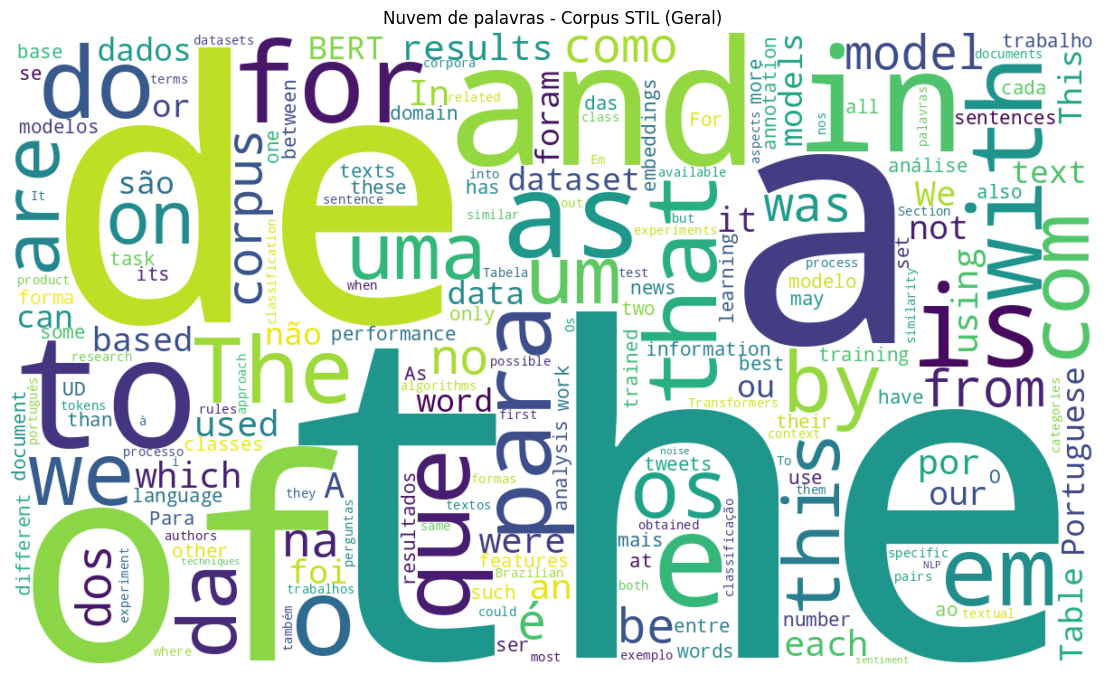

In [ ]:
gerar_wordcloud(final_corpus, "Nuvem de palavras - Corpus STIL (Geral)")

### Português

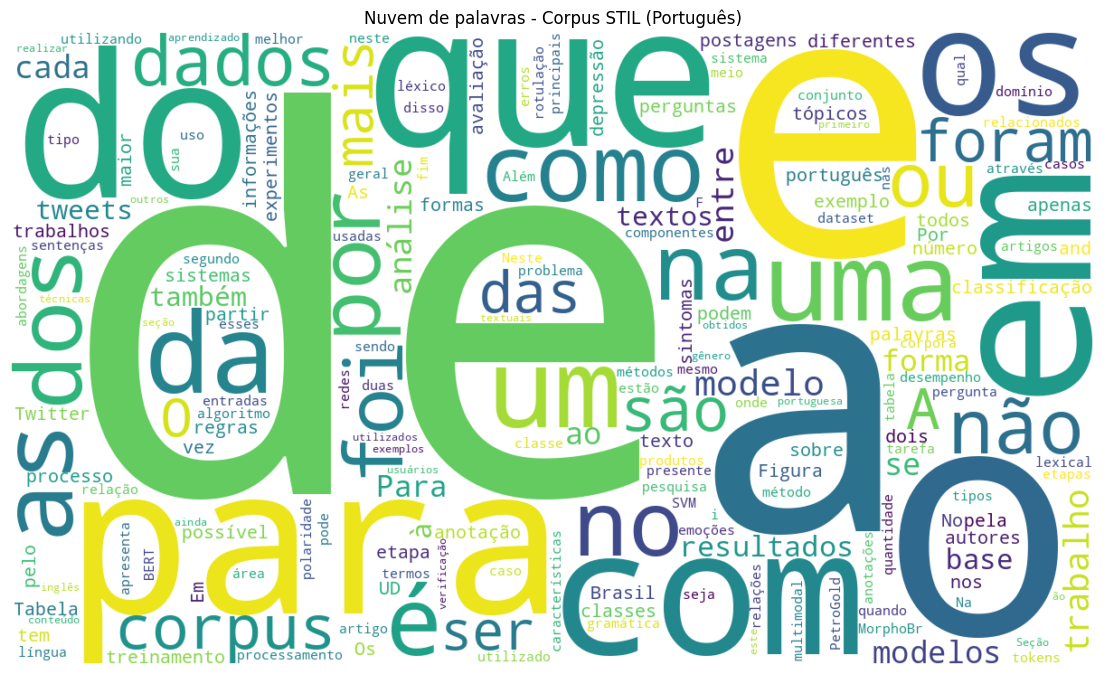

In [ ]:
gerar_wordcloud(corpus_pt, "Nuvem de palavras - Corpus STIL (Português)")

### Inglês

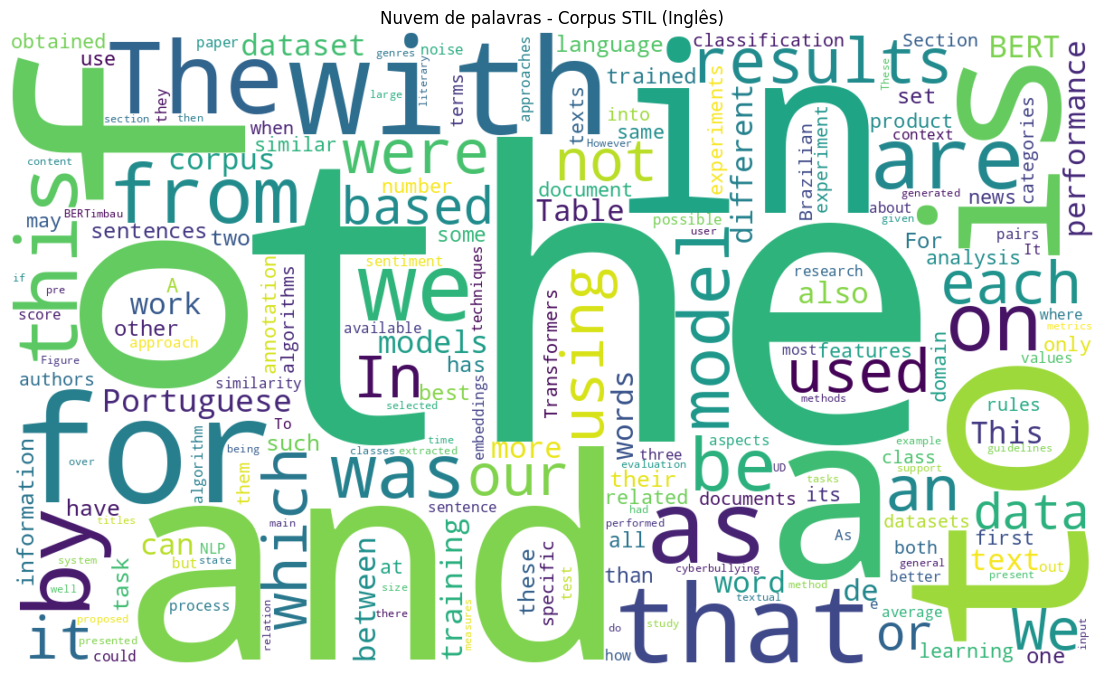

In [ ]:
gerar_wordcloud(corpus_en, "Nuvem de palavras - Corpus STIL (Inglês)")

## 11. Estatísticas por artigo e média lexical

Tokens, types, sentenças e unidades lexicais por artigo individual. A caixa é preservada nos types.

In [ ]:
rows = []
for art, art_raw in zip(final_corpus, articles):
    n_tokens = len(art["artigo_tokenizado"])
    n_types = len(set(art["artigo_tokenizado"]))
    rows.append({
        "titulo": art["titulo"],
        "idioma": art["idioma"],
        "tokens": n_tokens,
        "types": n_types,
        "sentencas": art_raw["n_sentencas"],
        "unidades_lexicais": art["n_unidades_lexicais"],
    })

df_estatisticas_por_artigo = pd.DataFrame(rows)
display(df_estatisticas_por_artigo)

print(f"Média geral de unidades lexicais por artigo: {df_estatisticas_por_artigo['unidades_lexicais'].mean():.2f}")
for idioma, media in df_estatisticas_por_artigo.groupby("idioma")["unidades_lexicais"].mean().items():
    print(f"Média de unidades lexicais por artigo ({idioma}): {media:.2f}")

,titulo,idioma,tokens,types,sentencas,unidades_lexicais
0,Porttinari - a Large Multi-genre Treebank for ...,Inglês,3744,1210,164,3744
1,Utilizando um dicionário morfológico para expa...,Português,2552,860,133,2552
2,Explorando a revisão de corpora por meio da co...,Português,3206,995,192,3206
3,PetroGold – Corpus padrão ouro para o domínio ...,Português,3056,1054,140,3056
4,Lexicalidade biomédica e sua mensuração em um ...,Português,2533,886,128,2533
5,Análise de polaridade e de tópicos em tweets n...,Português,2993,865,147,2993
6,Utilizando BERTimbau para a Classificação de E...,Português,1997,763,101,1997
7,Sentiment Analysis in Portuguese Texts from On...,Inglês,2147,819,119,2147
8,A Weakly Supervised Dataset of Fine-Grained Em...,Inglês,2601,853,156,2601
9,Learning rules for automatic identification of...,Inglês,3127,870,184,3127


Média geral de unidades lexicais por artigo: 2946.45
Média de unidades lexicais por artigo (Inglês): 3040.11
Média de unidades lexicais por artigo (Português): 2798.17
